In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sys import path

path.insert(0, '/Users/eliezerzucker/Documents/Glickman_Lab/lab_code')

from integrators import (
    perfect_integrator,
    leaky_integrator,
    confirmation_weighted_integrator,
    bayesian_integrator_with_noise,
    MU_HIGH, MU_LOW, SIGMA_M, N_FRAMES, K
)

from parameter_recovery import (
    generate_trials,
    simulate_choices,
    compute_nll_perfect,
    fit_model_perfect,
    run_recovery_perfect,
    run_recovery_leaky,
    run_recovery_confirmation,
    run_recovery_bayes_noise,
)


In [2]:
print("Running parameter recovery for perfect integrator...")
df_perfect = run_recovery_perfect(n_subjects=100, n_trials=200, h=0.1)

Running parameter recovery for perfect integrator...
  subject 10/100 done
  subject 20/100 done
  subject 30/100 done
  subject 40/100 done
  subject 50/100 done
  subject 60/100 done
  subject 70/100 done
  subject 80/100 done
  subject 90/100 done
  subject 100/100 done


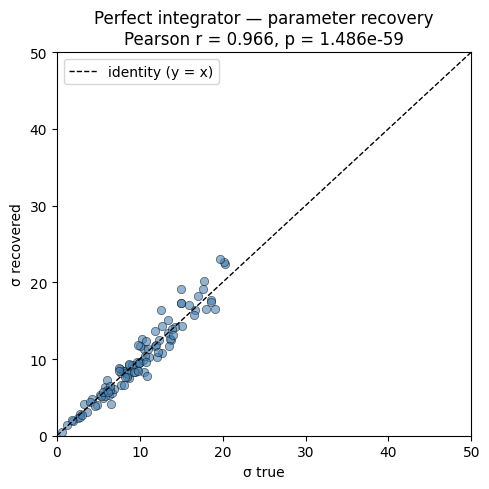

       sigma_true  sigma_recovered      nll
count     100.000          100.000  100.000
mean        9.926            9.944   63.038
std         4.669            5.095   25.765
min         0.596            0.500    4.567
25%         6.429            6.046   43.940
50%         9.725            9.255   65.072
75%        12.855           12.710   81.464
max        20.282           23.013  112.924


In [3]:
fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(df_perfect["sigma_true"], df_perfect["sigma_recovered"],
           alpha=0.6, edgecolors='k', linewidths=0.5, color='steelblue')

lims = [0, 50]
ax.plot(lims, lims, 'k--', linewidth=1, label='identity (y = x)')

r, p = pearsonr(df_perfect["sigma_true"], df_perfect["sigma_recovered"])
ax.set_xlabel("σ true")
ax.set_ylabel("σ recovered")
ax.set_title(f"Perfect integrator — parameter recovery\nPearson r = {r:.3f}, p = {p:.3e}")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.legend()

plt.tight_layout()
plt.show()

print(df_perfect.describe().round(3))

Running parameter recovery for leaky integrator...
  subject 10/100 done
  subject 20/100 done
  subject 30/100 done
  subject 40/100 done
  subject 50/100 done
  subject 60/100 done
  subject 70/100 done
  subject 80/100 done
  subject 90/100 done
  subject 100/100 done


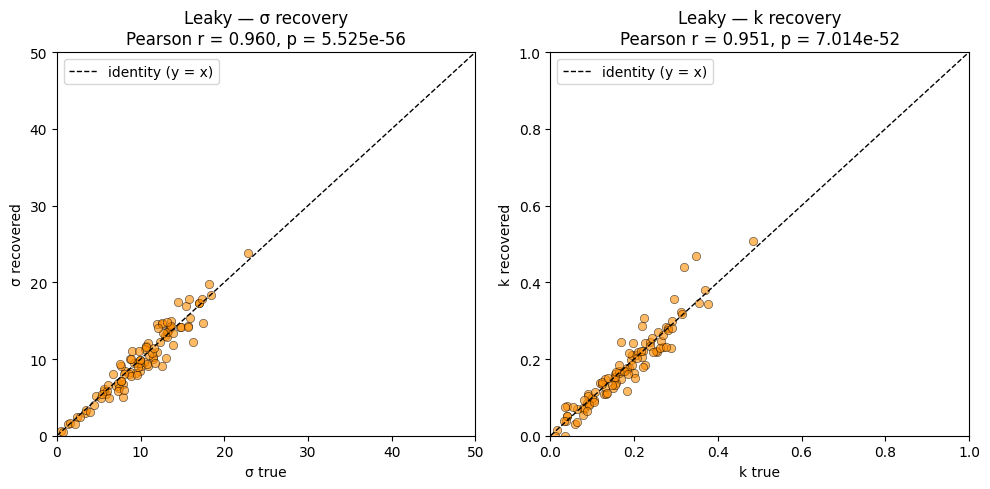

       sigma_true  sigma_recovered   k_true  k_recovered      nll
count     100.000          100.000  100.000      100.000  100.000
mean       10.127            9.986    0.178        0.178   66.502
std         4.368            4.620    0.093        0.100   24.503
min         0.549            0.500    0.010        0.000    3.714
25%         7.545            6.691    0.104        0.108   51.915
50%         9.963            9.695    0.177        0.168   67.598
75%        13.145           13.566    0.239        0.232   84.818
max        22.863           23.875    0.484        0.508  113.192


In [4]:
print("Running parameter recovery for leaky integrator...")
df_leaky = run_recovery_leaky(n_subjects=100, n_trials=200, h=0.1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, true_col, rec_col, label, lims in zip(
    axes,
    ["sigma_true", "k_true"],
    ["sigma_recovered", "k_recovered"],
    ["σ", "k"],
    [(0, 50), (0, 1)]
):
    ax.scatter(df_leaky[true_col], df_leaky[rec_col],
               alpha=0.6, edgecolors='k', linewidths=0.5, color='darkorange')
    ax.plot(lims, lims, 'k--', linewidth=1, label='identity (y = x)')

    r, p = pearsonr(df_leaky[true_col], df_leaky[rec_col])
    ax.set_xlabel(f"{label} true")
    ax.set_ylabel(f"{label} recovered")
    ax.set_title(f"Leaky — {label} recovery\nPearson r = {r:.3f}, p = {p:.3e}")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.legend()

plt.tight_layout()
plt.show()

print(df_leaky.describe().round(3))

Running parameter recovery for confirmation weighted integrator...
  subject 10/100 done
  subject 20/100 done
  subject 30/100 done
  subject 40/100 done
  subject 50/100 done
  subject 60/100 done
  subject 70/100 done
  subject 80/100 done
  subject 90/100 done
  subject 100/100 done


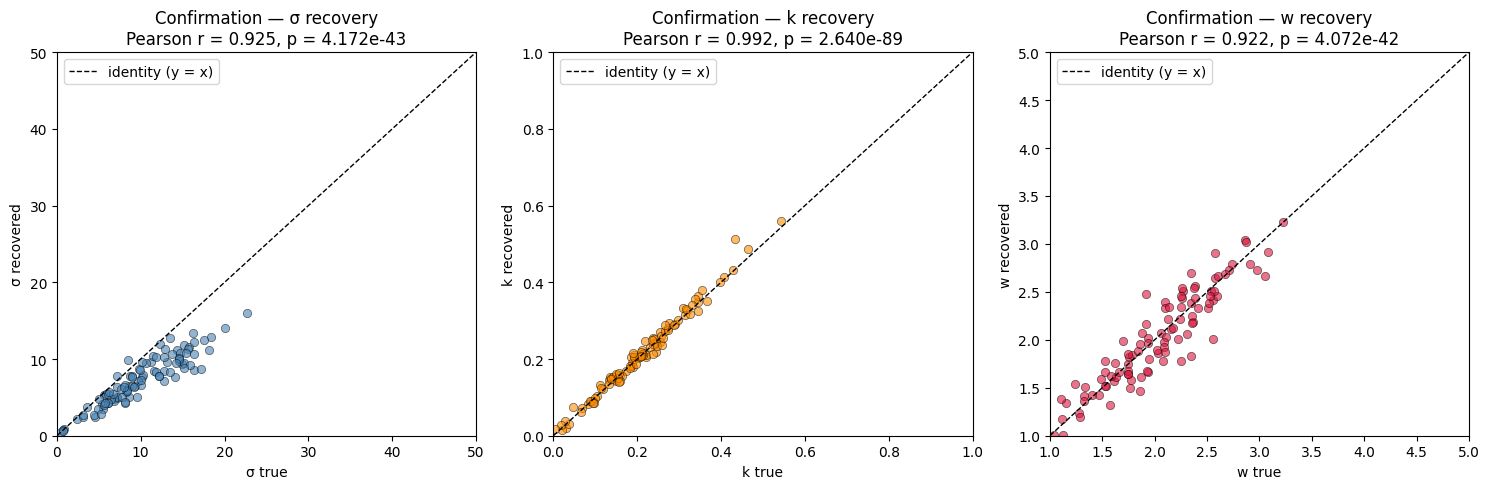

       sigma_true  sigma_recovered   k_true  k_recovered   w_true  \
count     100.000          100.000  100.000      100.000  100.000   
mean       10.082            7.366    0.210        0.214    2.044   
std         4.626            3.256    0.104        0.108    0.495   
min         0.501            0.500    0.004        0.016    1.040   
25%         6.747            4.982    0.141        0.145    1.730   
50%         9.617            7.625    0.208        0.209    2.084   
75%        13.824            9.637    0.266        0.274    2.368   
max        22.637           15.963    0.543        0.559    3.229   

       w_recovered      nll  
count      100.000  100.000  
mean         2.032  239.150  
std          0.496   98.191  
min          1.005   13.783  
25%          1.644  162.451  
50%          1.996  245.426  
75%          2.433  311.523  
max          3.231  442.850  


In [7]:
print("Running parameter recovery for confirmation weighted integrator...")
df_confirmation = run_recovery_confirmation(n_subjects=100, n_trials=1000, h=0.1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, true_col, rec_col, label, lims, color in zip(
    axes,
    ["sigma_true", "k_true",   "w_true"],
    ["sigma_recovered", "k_recovered", "w_recovered"],
    ["σ", "k", "w"],
    [(0, 50), (0, 1), (1, 5)],
    ["steelblue", "darkorange", "crimson"]
):
    ax.scatter(df_confirmation[true_col], df_confirmation[rec_col],
               alpha=0.6, edgecolors='k', linewidths=0.5, color=color)
    ax.plot(lims, lims, 'k--', linewidth=1, label='identity (y = x)')

    r, p = pearsonr(df_confirmation[true_col], df_confirmation[rec_col])
    ax.set_xlabel(f"{label} true")
    ax.set_ylabel(f"{label} recovered")
    ax.set_title(f"Confirmation — {label} recovery\nPearson r = {r:.3f}, p = {p:.3e}")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.legend()

plt.tight_layout()
plt.show()

print(df_confirmation.describe().round(3))

In [6]:
print("=== Parameter recovery quality check (r > 0.75 required) ===\n")

for df, model, pairs in [
    (df_perfect,      "Perfect",      [("sigma_true", "sigma_recovered", "σ")]),
    (df_leaky,        "Leaky",        [("sigma_true", "sigma_recovered", "σ"), ("k_true", "k_recovered", "k")]),
    (df_confirmation, "Confirmation", [("sigma_true", "sigma_recovered", "σ"), ("k_true", "k_recovered", "k"), ("w_true", "w_recovered", "w")]),
]:
    print(f"--- {model} integrator ---")
    for true_col, rec_col, label in pairs:
        r, p = pearsonr(df[true_col], df[rec_col])
        status = "PASS" if r > 0.75 else "FAIL"
        print(f"  {label}: r = {r:.3f} — {status}")
    print()

=== Parameter recovery quality check (r > 0.75 required) ===

--- Perfect integrator ---
  σ: r = 0.966 — PASS

--- Leaky integrator ---
  σ: r = 0.960 — PASS
  k: r = 0.951 — PASS

--- Confirmation integrator ---
  σ: r = 0.943 — PASS
  k: r = 0.990 — PASS
  w: r = 0.872 — PASS



In [ ]:
print("Running parameter recovery for Bayesian integrator with noise...")
df_bayes_noise = run_recovery_bayes_noise(n_subjects=100, n_trials=200, h=0.1)


In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))

ax.scatter(df_bayes_noise["sigma_true"], df_bayes_noise["sigma_recovered"],
           alpha=0.6, edgecolors='k', linewidths=0.5, color='purple')

lims = [0, 50]
ax.plot(lims, lims, 'k--', linewidth=1, label='identity (y = x)')

r, p = pearsonr(df_bayes_noise["sigma_true"], df_bayes_noise["sigma_recovered"])
ax.set_xlabel("σ true")
ax.set_ylabel("σ recovered")
ax.set_title(f"Bayesian+Noise — parameter recovery\nPearson r = {r:.3f}, p = {p:.3e}")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.legend()

plt.tight_layout()
plt.show()

print(df_bayes_noise.describe().round(3))


In [ ]:
print("=== Parameter recovery quality check (r > 0.75 required) ===\n")

for df, model, pairs in [
    (df_perfect,      "Perfect",      [("sigma_true", "sigma_recovered", "σ")]),
    (df_leaky,        "Leaky",        [("sigma_true", "sigma_recovered", "σ"), ("k_true", "k_recovered", "k")]),
    (df_confirmation, "Confirmation", [("sigma_true", "sigma_recovered", "σ"), ("k_true", "k_recovered", "k"), ("w_true", "w_recovered", "w")]),
    (df_bayes_noise,  "Bayesian+Noise", [("sigma_true", "sigma_recovered", "σ")]),
]:
    print(f"--- {model} integrator ---")
    for true_col, rec_col, label in pairs:
        r, p = pearsonr(df[true_col], df[rec_col])
        status = "PASS" if r > 0.75 else "FAIL"
        print(f"  {label}: r = {r:.3f} — {status}")
    print()
